# PSTHs → `psth_{subject}_{session}_{unit}.pdf`

One figure per unit, three rows by three columns.

Each **row** is a family of stimulus conditions — one object, two objects `psth_lib.SEP1_DEG` = 90° apart,
two objects antipodal — and each **column** shows those same conditions three ways: the
selected prototypes as chords on the ring, their PSTHs over the trial, and the dense tuning
over every orientation of that row's condition. A condition's colour is its mean firing rate
over `common.FR_WINDOW` (0–2000 ms), so the three columns are keyed to each other.

A trial joins a prototype when **both** of its objects are within `SIMILARITY_WINDOW_DEG` of
their slot. The stimulus set is discrete and never places two objects closer than about 80°,
so the trials in a prototype's bin are not centred on it; the panels are keyed to the nominal
prototypes, which is what the PSTHs and the colours refer to.

In [1]:
import matplotlib.pyplot as plt

import common
import psth_lib

common.set_style()

# (subject, session, unit, prototype orientation in degrees, share the 2-object colour scale)
# The orientation rotates every prototype set, to line the conditions up with that unit's
# receptive field. Sharing the colour scale makes the two 2-object rows comparable to each
# other; without it each row is normalized to its own range.
UNITS = [
    ('Perle', '2022-06-11', 188, 48, True),
    ('Perle', '2022-06-11', 126, 11, False),
    ('Perle', '2022-06-11', 143, 88, False),
    ('Perle', '2022-06-10', 47, 0, False),
]

FIGSIZE = (6.0, 4.5)
OUTPUT = 'psth_{subject}_{session}_{unit_id}.pdf'

SIMILARITY_WINDOW_DEG = 15.0  # both objects must be within this of their prototype slot
SMOOTH_HALF_WIN_MS = 250.0    # temporal smoothing half-window of the firing rates
N_PROTO = 4                   # prototypes per row, in columns 0 and 1


Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 188 @ s0/good (1170 trials with spikes) | prototypes at 48°
mean response time 2242 ms after stimulus onset
saved psth_Perle_2022-06-11_188.pdf


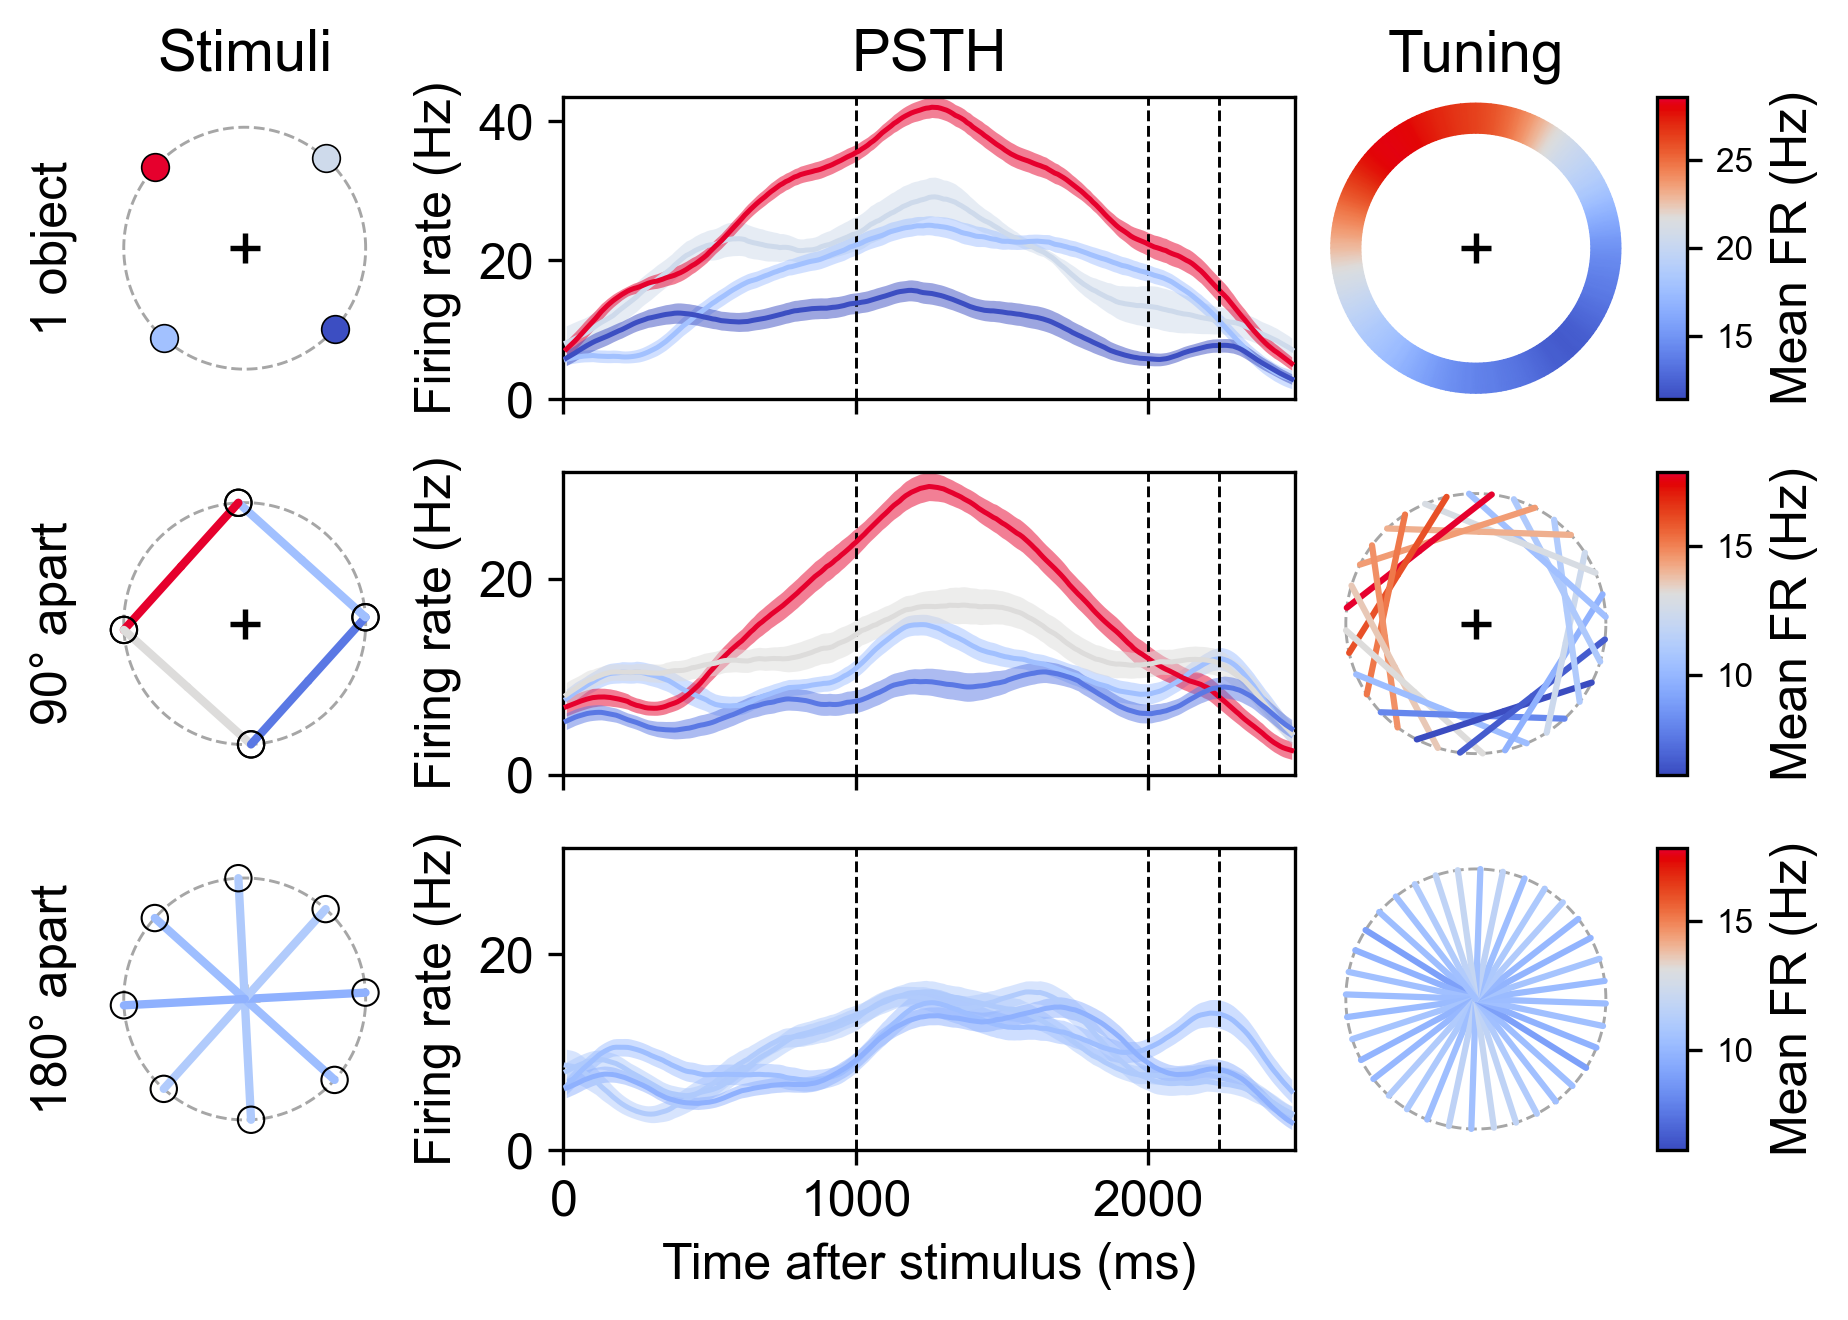

Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 126 @ s0/good (1170 trials with spikes) | prototypes at 11°
mean response time 2243 ms after stimulus onset
saved psth_Perle_2022-06-11_126.pdf


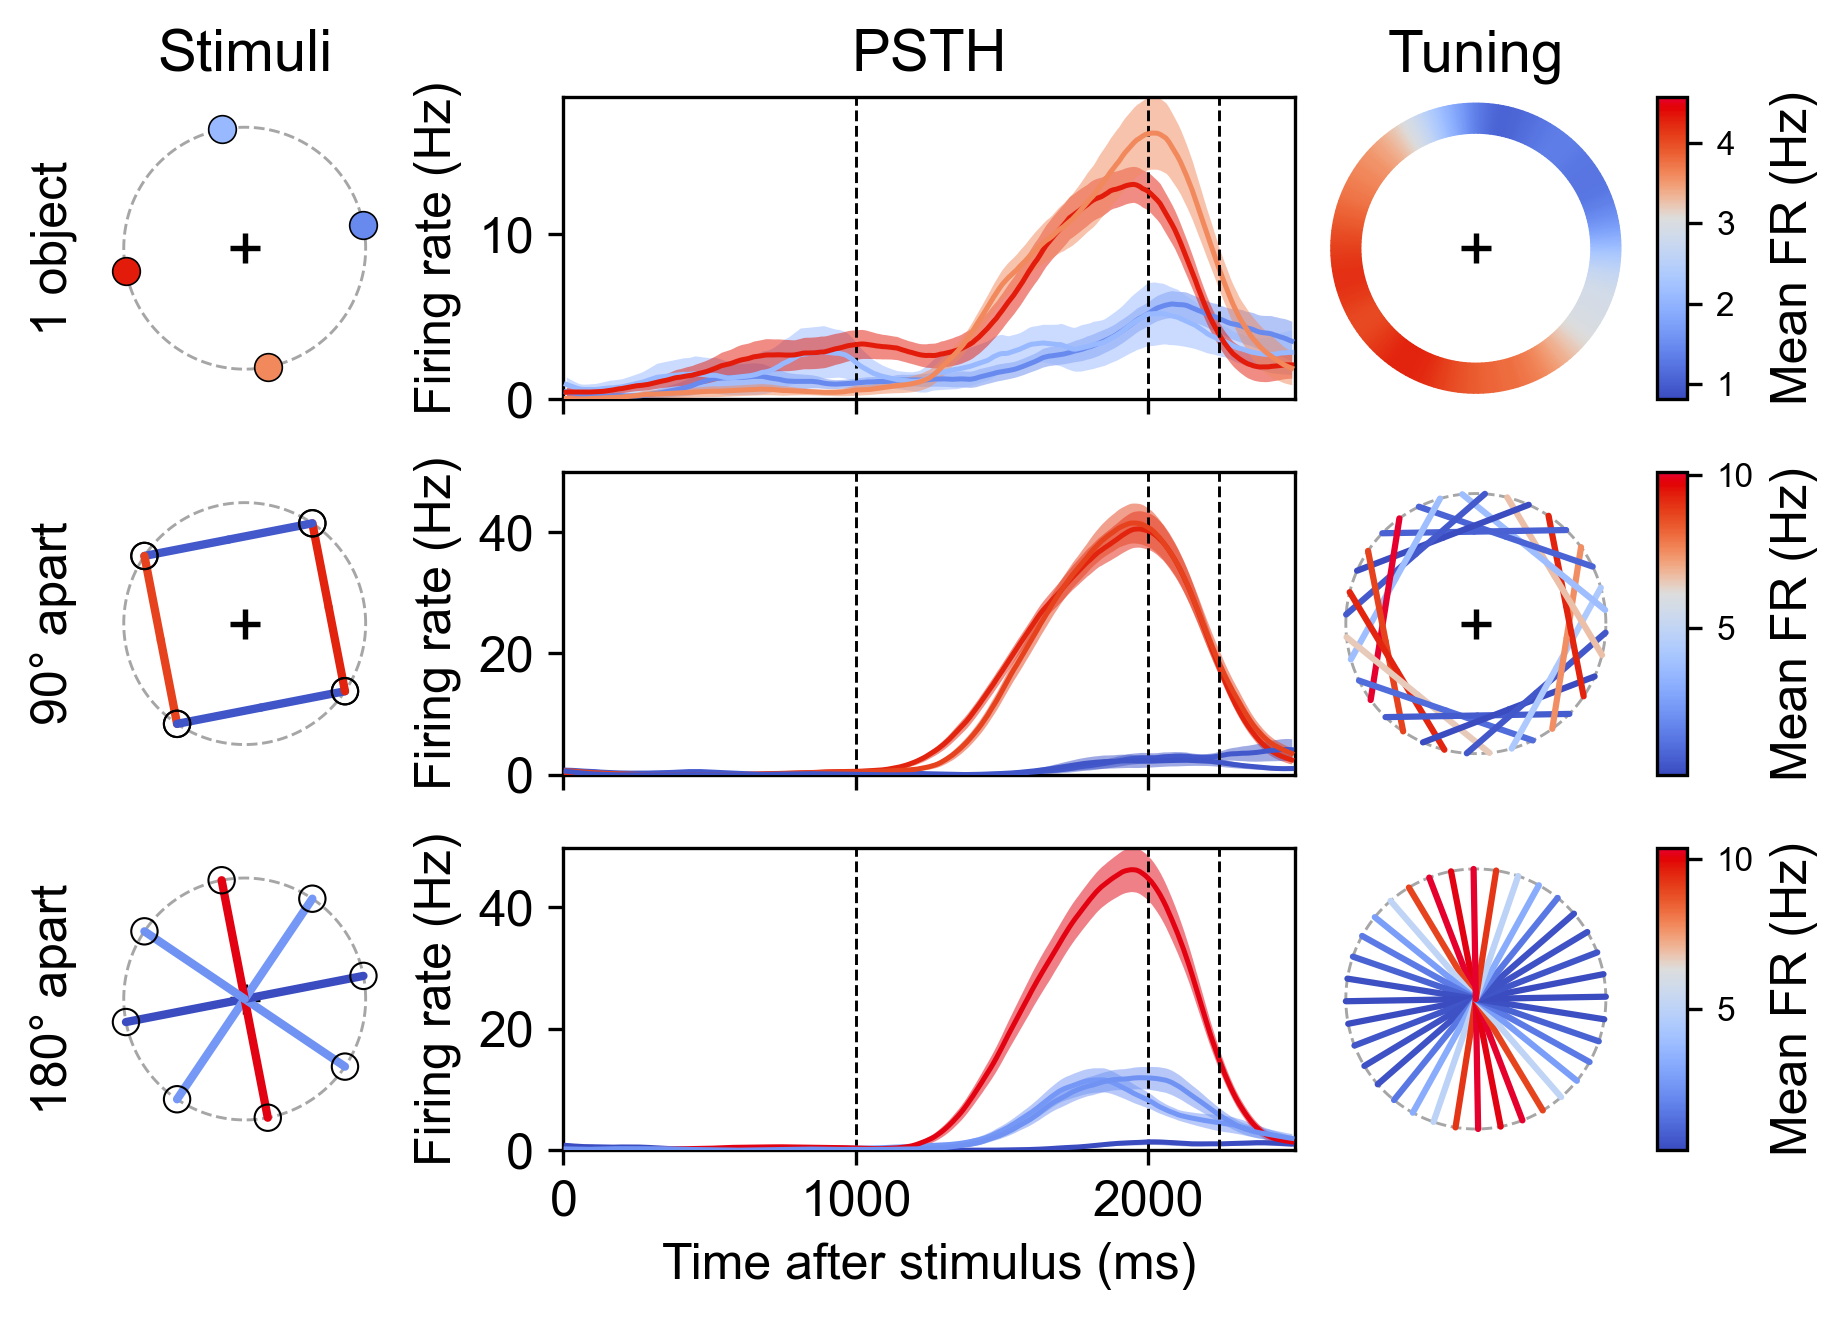

Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 143 @ s0/good (1170 trials with spikes) | prototypes at 88°
mean response time 2241 ms after stimulus onset
saved psth_Perle_2022-06-11_143.pdf


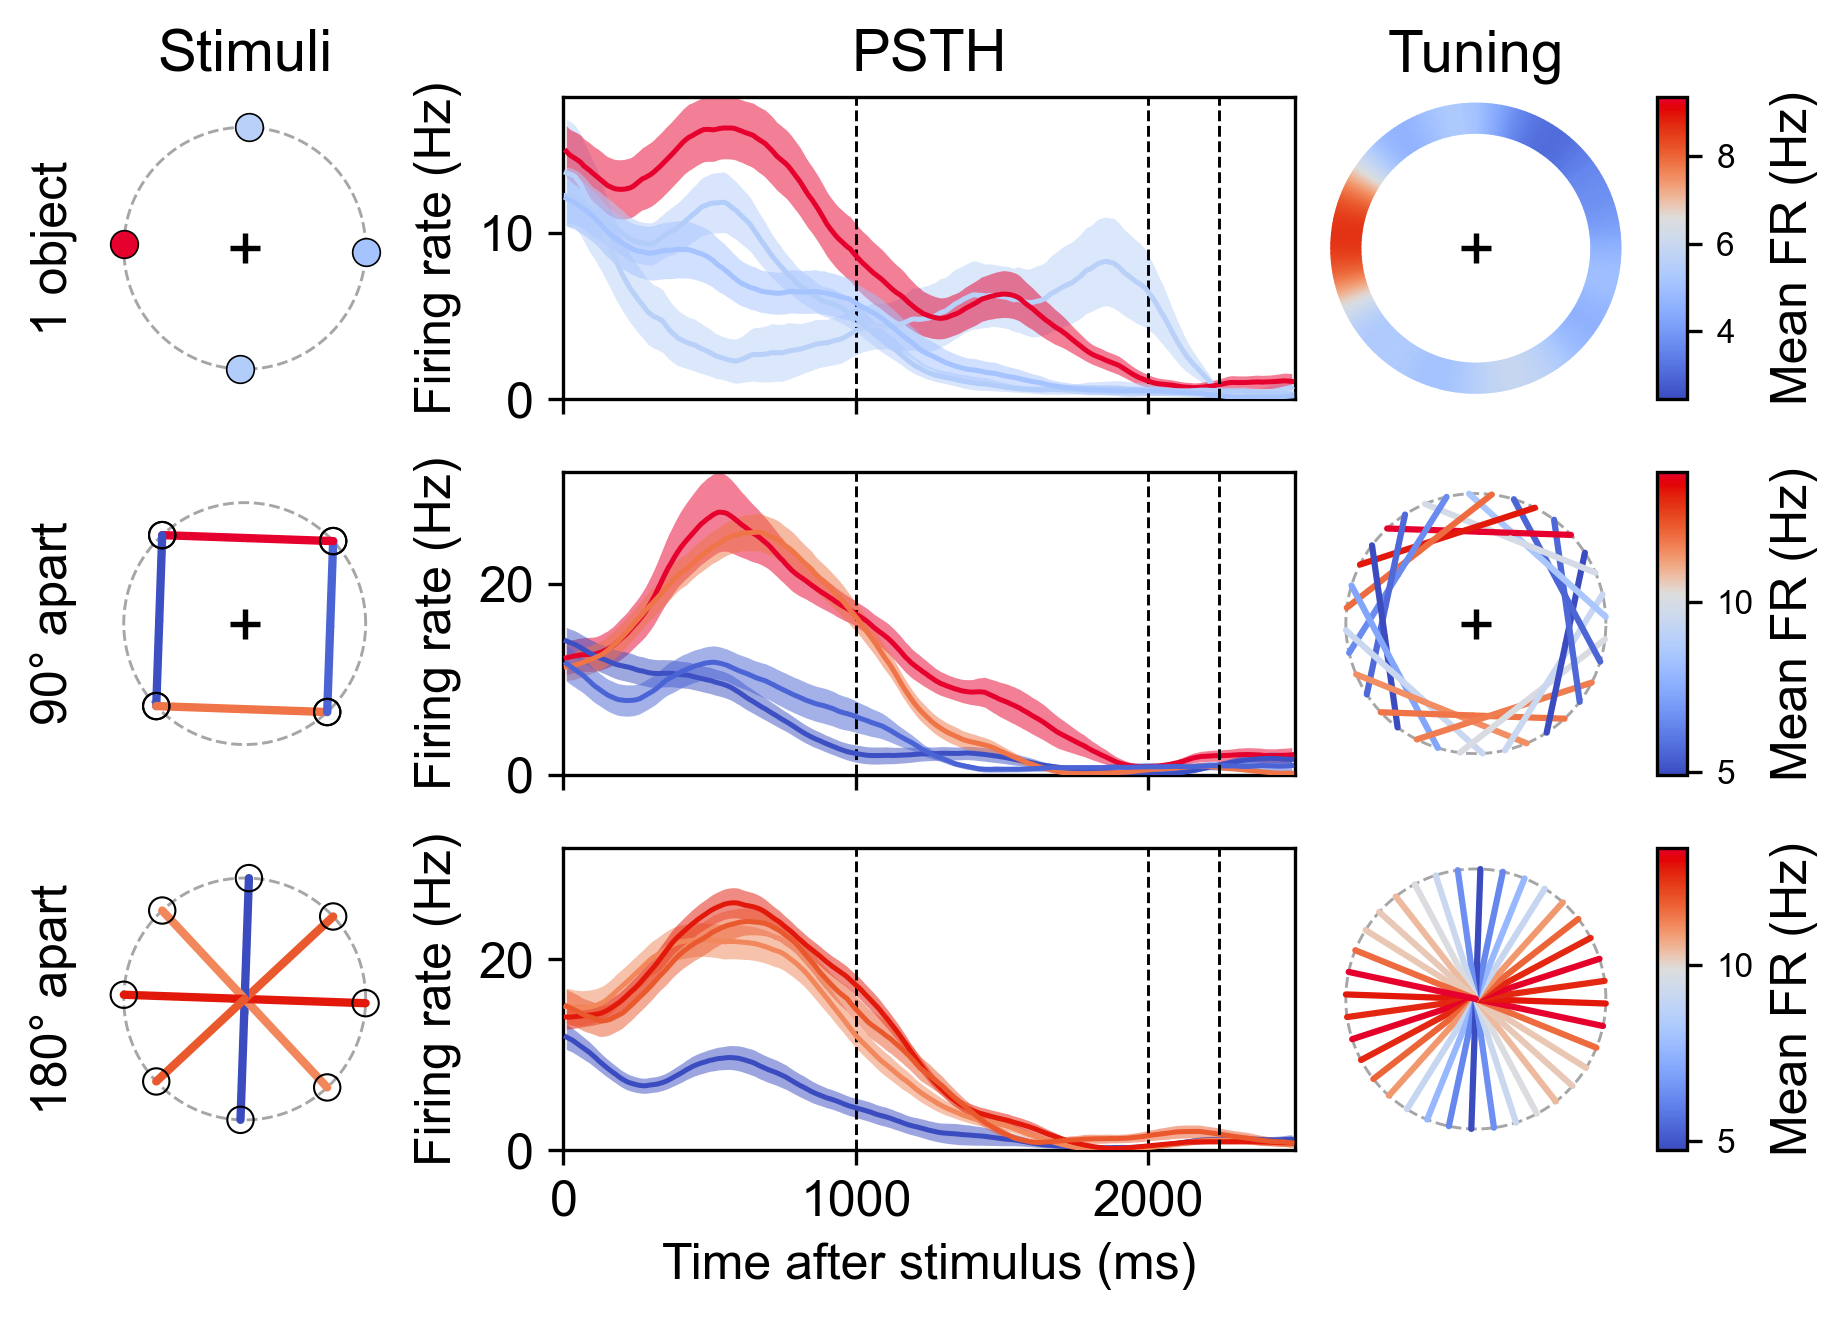

Perle 2022-06-10: 962 2-obj + 198 1-obj trials | unit 47 @ vprobe0/mua (1206 trials with spikes) | prototypes at 0°
mean response time 2245 ms after stimulus onset
saved psth_Perle_2022-06-10_47.pdf


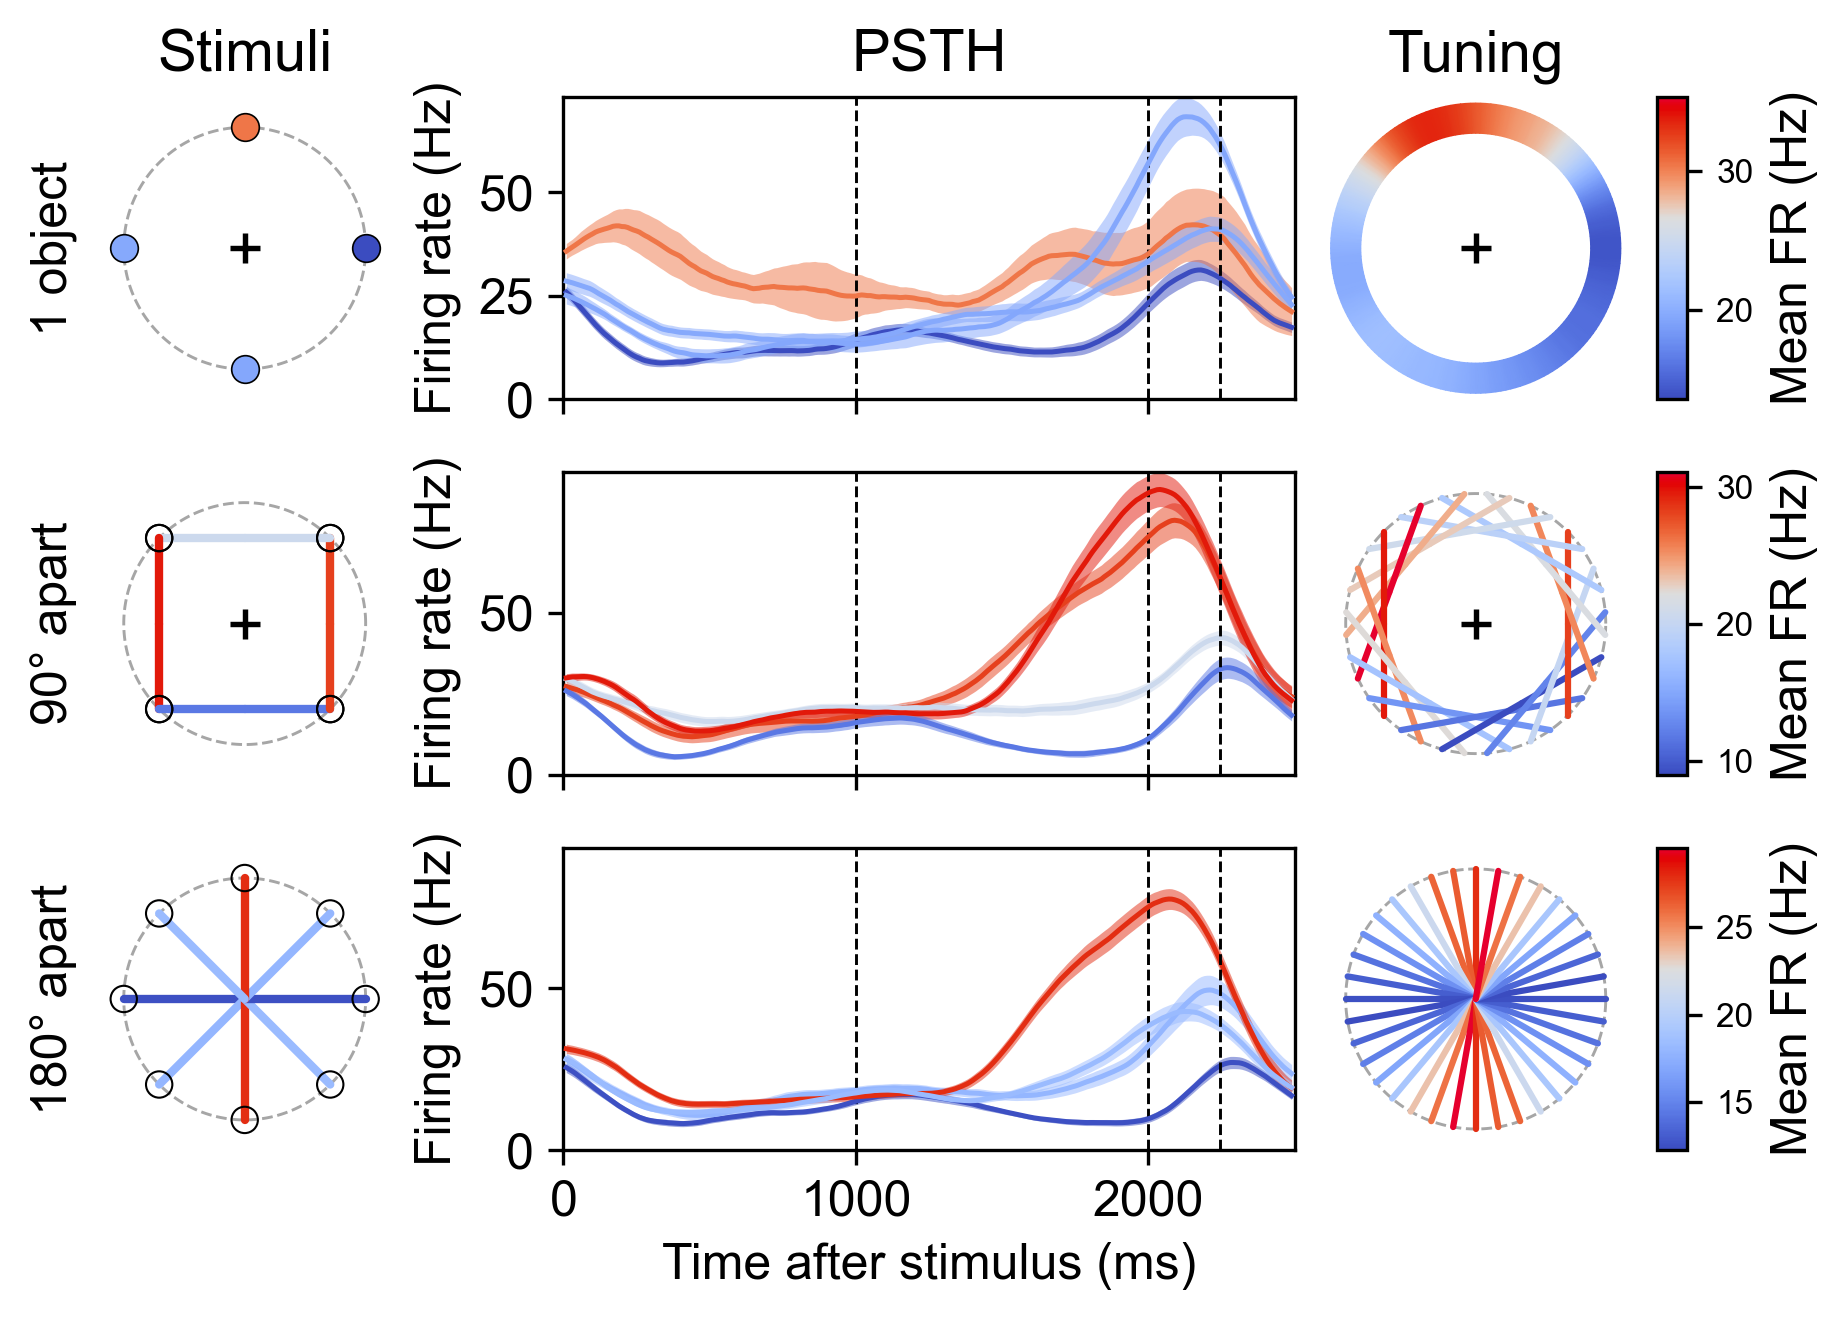

In [2]:
for subject, session, unit_id, orientation_deg, share_scale in UNITS:
    fig, _ = psth_lib.psth_figure(
        subject, session, unit_id, orientation_deg=orientation_deg,
        similarity_window_deg=SIMILARITY_WINDOW_DEG,
        smooth_half_win_ms=SMOOTH_HALF_WIN_MS,
        n_proto=N_PROTO, share_2obj_color_scale=share_scale,
        figsize=FIGSIZE)
    common.save(fig, OUTPUT.format(subject=subject, session=session, unit_id=unit_id))
    plt.show()